
# Project Milestone Pertemuan 5: Validasi, Kestabilan, dan Ensemble

Proyek Kelompok 7: Karakteristik Ekspresi Gen Berdasarkan Sampel (Reduksi Dimensi dan Pencarian Pola, fokus obat).

Pada pertemuan 5, kelompok menjawab tiga pertanyaan: (1) apakah performa model stabil ketika pembagian data berubah, (2) apakah ensemble learning meningkatkan performa dibanding model awal, dan (3) apakah distribusi kelas memengaruhi evaluasi.

**Penyesuaian untuk proyek kami.** Proyek ini adalah *unsupervised learning* (reduksi dimensi lalu clustering), jadi tidak ada target kelas. Karena itu:
- Pertanyaan 3 (distribusi kelas) tidak relevan. Sebagai gantinya kami mengikuti **Tugas 4 versi unsupervised**: kestabilan clustering, perbandingan konfigurasi, serta ukuran dan karakteristik cluster. Ketimpangan jumlah sel antar jaringan tetap kami periksa pada bagian ini.
- Ensemble berbasis pohon (Random Forest, Gradient Boosting, XGBoost) membutuhkan target, sehingga tidak dipakai. Padanan *unsupervised*-nya adalah **consensus clustering**, yaitu menggabungkan banyak hasil clustering menjadi satu.
- "Skor" tiap fold adalah **Silhouette** (kerapatan dan keterpisahan cluster pada sel validasi) dan **ARI** (seberapa sama pembagian cluster dengan model acuan).

**Alur:** baseline (PCA + K-Means) → kandidat model → validasi → ensemble → diagnosis awal.

| Output yang wajib dikumpulkan | Lokasi di notebook |
|---|---|
| Strategi validasi dan alasannya | Tugas 1 |
| Hasil validasi / cross-validation | Tugas 2 |
| Tabel perbandingan baseline dan kandidat | Tugas 3 |
| Eksperimen ensemble | Tugas 3 |
| Distribusi kelas / analisis imbalance | Tugas 4 (versi unsupervised: ukuran cluster dan ketimpangan jaringan) |
| Interpretasi hasil dan keterbatasan | Bagian Ringkasan dan Keterbatasan |
| Rencana eksperimen Pertemuan 6-7 | Bagian Rencana |
| Jawaban checkpoint | Bagian terakhir |

Notebook berjalan dari atas ke bawah dan membaca langsung `GDSC_DATASET.csv` serta `CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz`. Tidak ada file baru yang disimpan. Waktu proses sekitar beberapa menit.


In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from scipy.stats import kruskal, false_discovery_control
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

# --- Parameter eksperimen (semua boleh diubah) ---
SEED = 42              # agar hasil bisa diulang
N_GEN = 2000           # ASUMSI: jumlah gen bervarians tertinggi (pilihan, bukan aturan)
AMBANG_TPM = 1         # gen aktif jika TPM > 1 ...
PROPORSI_SAMPEL = 0.10 # ... pada minimal 10% sampel
UKURAN_TEST = 0.20     # porsi data yang dikunci sebagai test set
N_FOLD = 5             # jumlah fold validasi silang


## Bagian 0. Persiapan data

Data dibangun dengan **pipeline Langkah 1-4** dari notebook *Data Quality dan Pipeline* (muat data, rapikan identitas, cocokkan GDSC dengan CCLE, bangun tabel). Hasilnya 621 *cell line* dengan ekspresi TPM mentah.

**Langkah 6 (transformasi ekspresi) sengaja tidak dijalankan di sini.** Alasannya ada di Tugas 1: transformasi itu harus dipelajari ulang dari data latih di setiap fold, bukan dari seluruh data.


In [2]:
log = []
def catat(langkah, **info):
    log.append({"langkah": langkah, **info})

# --- Langkah 1. Muat dan rapikan identitas -------------------------------
gdsc = pd.read_csv("GDSC_DATASET.csv")
gdsc["DRUG_NAME"] = gdsc["DRUG_NAME"].str.strip()           # 'GSK-LSD1-2HCl ' -> tanpa spasi akhir
catat("1a. GDSC dimuat", baris=len(gdsc), cell_line=gdsc.COSMIC_ID.nunique(), obat=gdsc.DRUG_ID.nunique())

expr = (pd.read_csv("CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz", sep="\t")
          .drop(columns="transcript_ids")                  # tidak dipakai
          .set_index("gene_id")
          .T.astype("float32"))                            # baris = sampel, kolom = gen
expr.index.name = "ccle_sample"
catat("1b. CCLE dimuat dan ditranspose", sampel=expr.shape[0], gen=expr.shape[1])

In [3]:
# --- Langkah 2. Kunci pencocokan ----------------------------------------
def norm(s):
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())

H = "HAEMATOPOIETIC_AND_LYMPHOID_TISSUE"
# Jaringan GDSC -> jaringan CCLE yang masuk akal. Dipakai hanya untuk
# menyelesaikan kunci ambigu dan menandai pasangan yang janggal.
KOMPAT = {
    "aero_dig_tract": {"UPPER_AERODIGESTIVE_TRACT", "OESOPHAGUS", "SALIVARY_GLAND"},
    "bone": {"BONE", "SOFT_TISSUE"}, "breast": {"BREAST"},
    "digestive_system": {"STOMACH", "LIVER", "BILIARY_TRACT", "SMALL_INTESTINE", "PANCREAS", "LARGE_INTESTINE", "OESOPHAGUS"},
    "kidney": {"KIDNEY"}, "large_intestine": {"LARGE_INTESTINE"},
    "leukemia": {H}, "lymphoma": {H}, "myeloma": {H},
    "lung": {"LUNG", "PLEURA"}, "lung_NSCLC": {"LUNG", "PLEURA"}, "lung_SCLC": {"LUNG", "PLEURA"},
    "nervous_system": {"CENTRAL_NERVOUS_SYSTEM"}, "neuroblastoma": {"AUTONOMIC_GANGLIA"},
    "pancreas": {"PANCREAS"}, "skin": {"SKIN"}, "soft_tissue": {"SOFT_TISSUE", "BONE"},
    "thyroid": {"THYROID"},
    "urogenital_system": {"OVARY", "ENDOMETRIUM", "URINARY_TRACT", "PROSTATE", "CERVIX", "KIDNEY", "SOFT_TISSUE"},
}
# Pasangan sah yang terlewat normalisasi (O vs 0). Ditambahkan manual.
MANUAL = {"786-0": "786O_KIDNEY", "U031": "UO31_KIDNEY"}

cells = (gdsc.drop_duplicates("COSMIC_ID")
             [["COSMIC_ID", "CELL_LINE_NAME", "GDSC Tissue descriptor 1"]]
             .rename(columns={"GDSC Tissue descriptor 1": "tissue_gdsc"}))
cells["key"] = cells.CELL_LINE_NAME.map(norm)

ccle = pd.DataFrame({"ccle_sample": expr.index})
ccle["key"] = ccle.ccle_sample.str.split("_", n=1).str[0].map(norm)
ccle["tissue_ccle"] = ccle.ccle_sample.str.split("_", n=1).str[1]

def jaringan_cocok(t_gdsc, t_ccle):
    return t_gdsc in KOMPAT and t_ccle in KOMPAT[t_gdsc]

# --- Langkah 3. Cocokkan -------------------------------------------------
kand = cells.merge(ccle, on="key")
kand["ambigu"] = (kand.groupby("key").COSMIC_ID.transform("nunique") > 1) | \
                 (kand.groupby("key").ccle_sample.transform("nunique") > 1)
kand["tissue_cocok"] = [jaringan_cocok(a, b) for a, b in zip(kand.tissue_gdsc, kand.tissue_ccle)]
catat("3a. Kandidat setelah normalisasi nama", pasangan=len(kand), ambigu=int(kand.ambigu.sum()))

unik = kand[~kand.ambigu].assign(metode="nama_unik")
selesai = kand[kand.ambigu & kand.tissue_cocok].assign(metode="nama+jaringan")
manual = pd.DataFrame([
    {"COSMIC_ID": r.COSMIC_ID, "CELL_LINE_NAME": r.CELL_LINE_NAME, "tissue_gdsc": r.tissue_gdsc, "key": r.key,
     "ccle_sample": c, "tissue_ccle": c.split("_", 1)[1], "metode": "manual"}
    for n, c in MANUAL.items() for r in cells[cells.CELL_LINE_NAME == n].itertuples()
])
peta = pd.concat([unik, selesai, manual], ignore_index=True).drop(columns=["ambigu", "tissue_cocok"])
peta["tissue_cocok"] = [jaringan_cocok(a, b) for a, b in zip(peta.tissue_gdsc, peta.tissue_ccle)]
catat("3b. Pemetaan akhir 1:1", cell_line=len(peta), nama_unik=len(unik), nama_jaringan=len(selesai), manual=len(manual))

In [4]:
# --- Langkah 4. Bangun tiga tabel ---------------------------------------
peta = peta.sort_values("COSMIC_ID").reset_index(drop=True)

# 4a. Matriks ekspresi (baris diberi COSMIC_ID agar bisa digabung dengan GDSC)
ekspresi = expr.loc[peta.ccle_sample].copy()
ekspresi.index = peta.COSMIC_ID.values
ekspresi.index.name = "COSMIC_ID"

# 4b. Metadata satu baris per cell line
meta_cols = ["COSMIC_ID", "TCGA_DESC", "GDSC Tissue descriptor 1", "GDSC Tissue descriptor 2",
             "Cancer Type (matching TCGA label)", "Microsatellite instability Status (MSI)",
             "Screen Medium", "Growth Properties"]
metadata = (peta[["COSMIC_ID", "CELL_LINE_NAME", "ccle_sample", "tissue_ccle", "metode", "tissue_cocok"]]
            .merge(gdsc.drop_duplicates("COSMIC_ID")[meta_cols], on="COSMIC_ID", how="left"))
metadata["metadata_gdsc_lengkap"] = metadata["GDSC Tissue descriptor 1"].notna()

# 4c. Respons obat: hanya cell line yang punya ekspresi. Kunci obat = DRUG_ID.
resp_cols = ["COSMIC_ID", "DRUG_ID", "DRUG_NAME", "LN_IC50", "AUC", "Z_SCORE", "TARGET", "TARGET_PATHWAY"]
respons = gdsc.loc[gdsc.COSMIC_ID.isin(peta.COSMIC_ID), resp_cols].reset_index(drop=True)

catat("4. Tabel akhir", ekspresi_baris=ekspresi.shape[0], ekspresi_gen=ekspresi.shape[1],
      respons_baris=len(respons), respons_obat_id=respons.DRUG_ID.nunique())

In [5]:
# Matriks ekspresi mentah (TPM) dan label jaringan untuk stratifikasi
assert (metadata.COSMIC_ID.to_numpy() == ekspresi.index.to_numpy()).all()
X = ekspresi.to_numpy()                       # 621 x 57.820, TPM mentah (BELUM ditransformasi)
ids = ekspresi.index.to_numpy()

# Jaringan dengan kurang dari 10 sel digabung menjadi LAINNYA agar bisa dibagi merata antar fold
jumlah = metadata.tissue_ccle.value_counts()
jaringan = metadata.tissue_ccle.where(metadata.tissue_ccle.map(jumlah) >= 10, "LAINNYA").to_numpy()
print("Data:", X.shape)
print(pd.Series(jaringan).value_counts().to_string())

Data: (621, 57820)
LUNG                                  131
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE    103
BREAST                                 45
LARGE_INTESTINE                        40
CENTRAL_NERVOUS_SYSTEM                 33
SKIN                                   32
PANCREAS                               28
OVARY                                  28
LAINNYA                                27
OESOPHAGUS                             24
STOMACH                                22
URINARY_TRACT                          16
UPPER_AERODIGESTIVE_TRACT              15
KIDNEY                                 15
SOFT_TISSUE                            14
BONE                                   13
LIVER                                  13
AUTONOMIC_GANGLIA                      12
ENDOMETRIUM                            10



# Tugas 1. Audit strategi validasi

## 1.1 Hasil audit

| Pertanyaan audit | Temuan | Keputusan |
|---|---|---|
| Bagaimana data dibagi menjadi training dan testing? | Pada pipeline sebelumnya seluruh 621 sel dipakai sekaligus tanpa pembagian, sehingga tidak ada data yang benar-benar "belum dilihat". Cukup untuk eksplorasi, tetapi tidak cukup untuk menilai apakah hasil bertahan pada sel baru | 80% development set (496 sel) dan 20% test set (125 sel). Development set dinilai dengan 5-fold cross-validation |
| Apakah validation set diperlukan untuk tuning? | Ya. Ada beberapa pilihan yang harus ditentukan: jumlah cluster (k), jumlah komponen PCA, metode clustering, dan jumlah gen (N_GEN). Bila dipilih memakai seluruh data, hasilnya terlalu optimis | Semua pilihan ditentukan memakai fold validasi dari cross-validation pada development set |
| Apakah pembagian sesuai jenis masalah? | Masalah ini *unsupervised*: tidak ada target kelas, jadi yang dinilai adalah kualitas dan kestabilan cluster. Pembagian dibuat *stratified* menurut jaringan asal sel agar tiap bagian punya komposisi jaringan yang mirip. Label jaringan **tidak** dipakai untuk membentuk cluster | `StratifiedKFold` berdasarkan jaringan. Jaringan dengan kurang dari 10 sel digabung menjadi `LAINNYA` (27 sel) supaya bisa dibagi merata |
| Apakah preprocessing dipelajari hanya dari data training? | **Tidak**, pada pipeline sebelumnya. Filter gen aktif, pemilihan 2.000 gen bervarians tertinggi, dan standardisasi dihitung dari seluruh 621 sel, sehingga sel validasi ikut menentukan gen mana yang terpilih (kebocoran data ringan) | Langkah 6 dibuat sebagai kelas `Transformasi` yang dipelajari ulang dari data latih di setiap fold. Sel validasi hanya ditransformasi memakai parameter dari data latih |
| Apakah data test sudah dipakai berulang untuk memilih model? | Belum. Test set belum pernah dipakai | Test set tetap dikunci dan dipakai **satu kali** untuk model final di Pertemuan 7. Kode memiliki `assert` agar test set tidak ikut ke development set |

## 1.2 Fungsi tiap bagian data (hold-out)

| Bagian | Fungsi pada proyek ini |
|---|---|
| Training (bagian hijau tiap fold) | Mempelajari transformasi (gen terpilih, rata-rata, simpangan baku), PCA, dan membentuk cluster |
| Validation (bagian oranye tiap fold) | Menetapkan cluster untuk sel yang tidak ikut membentuk model, lalu menilai kualitas dan kestabilannya. Dipakai untuk memilih konfigurasi dan membandingkan kandidat |
| Test (dikunci) | Mengevaluasi model terpilih pada tahap akhir, sekali saja |


In [6]:
# Pembagian data
semua = np.arange(len(X))
dev, test = train_test_split(semua, test_size=UKURAN_TEST, stratify=jaringan, random_state=SEED)

skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
lipatan = list(skf.split(dev, jaringan[dev]))

print(f"Development set: {len(dev)} sel | Test set (dikunci): {len(test)} sel")
print("Tidak ada sel yang sama di dev dan test:", np.intersect1d(dev, test).size == 0)

# komposisi jaringan tiap bagian (persen), untuk memastikan pembagian merata
komposisi = pd.DataFrame({"semua": pd.Series(jaringan).value_counts(normalize=True)})
komposisi["dev"] = pd.Series(jaringan[dev]).value_counts(normalize=True)
komposisi["test"] = pd.Series(jaringan[test]).value_counts(normalize=True)
for i, (a, b) in enumerate(lipatan, 1):
    komposisi[f"fold{i}_val"] = pd.Series(jaringan[dev[b]]).value_counts(normalize=True)
display((komposisi.fillna(0) * 100).round(1))
print("Ukuran tiap fold (latih / validasi):", [(len(a), len(b)) for a, b in lipatan])

Development set: 496 sel | Test set (dikunci): 125 sel
Tidak ada sel yang sama di dev dan test: True


,semua,dev,test,fold1_val,fold2_val,fold3_val,fold4_val,fold5_val
LUNG,21.1,21.2,20.8,21.0,21.2,21.2,21.2,21.2
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,16.6,16.5,16.8,17.0,17.2,16.2,16.2,16.2
BREAST,7.2,7.3,7.2,8.0,7.1,7.1,7.1,7.1
LARGE_INTESTINE,6.4,6.5,6.4,6.0,6.1,7.1,7.1,6.1
CENTRAL_NERVOUS_SYSTEM,5.3,5.2,5.6,5.0,6.1,5.1,5.1,5.1
SKIN,5.2,5.2,4.8,5.0,6.1,5.1,5.1,5.1
PANCREAS,4.5,4.4,4.8,4.0,4.0,5.1,5.1,4.0
OVARY,4.5,4.4,4.8,4.0,4.0,5.1,5.1,4.0
LAINNYA,4.3,4.4,4.0,4.0,5.1,5.1,4.0,4.0
OESOPHAGUS,3.9,3.8,4.0,4.0,4.0,4.0,3.0,4.0


Ukuran tiap fold (latih / validasi): [(396, 100), (397, 99), (397, 99), (397, 99), (397, 99)]


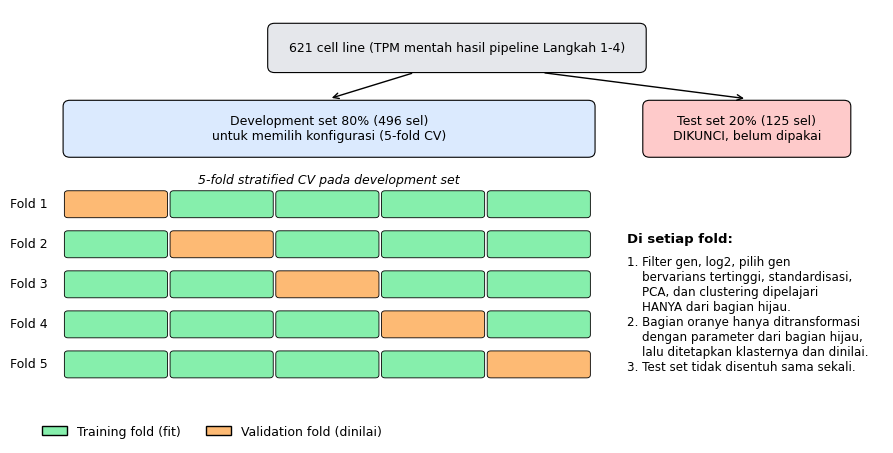

In [7]:
# Diagram pembagian data
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.set_xlim(0, 100); ax.set_ylim(0, 56); ax.axis("off")

def kotak(x, y, w, h, teks, warna, ukuran=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.2,rounding_size=0.8", fc=warna, ec="black", lw=0.8))
    ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", fontsize=ukuran)

kotak(28, 48, 44, 6, f"{len(X)} cell line (TPM mentah hasil pipeline Langkah 1-4)", "#e5e7eb")
kotak(4, 37, 62, 7, f"Development set 80% ({len(dev)} sel)\nuntuk memilih konfigurasi (5-fold CV)", "#dbeafe")
kotak(72, 37, 24, 7, f"Test set 20% ({len(test)} sel)\nDIKUNCI, belum dipakai", "#fecaca")
ax.annotate("", xy=(35, 44.4), xytext=(45, 47.8), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(84, 44.4), xytext=(60, 47.8), arrowprops=dict(arrowstyle="->"))

for f in range(N_FOLD):
    y = 29 - f * 5.2
    ax.text(2, y + 1.7, f"Fold {f + 1}", ha="right", va="center", fontsize=9)
    for j in range(N_FOLD):
        warna = "#fdba74" if j == f else "#86efac"
        ax.add_patch(FancyBboxPatch((4 + j * 12.4, y), 12.0, 3.4, boxstyle="round,pad=0.05,rounding_size=0.4", fc=warna, ec="black", lw=0.6))
ax.text(35, 33.4, "5-fold stratified CV pada development set", ha="center", fontsize=9, style="italic")

ax.text(70, 27, "Di setiap fold:", fontsize=9.5, weight="bold", va="top")
ax.text(70, 24, "1. Filter gen, log2, pilih gen\n    bervarians tertinggi, standardisasi,\n    PCA, dan clustering dipelajari\n    HANYA dari bagian hijau.\n"
        "2. Bagian oranye hanya ditransformasi\n    dengan parameter dari bagian hijau,\n    lalu ditetapkan klasternya dan dinilai.\n"
        "3. Test set tidak disentuh sama sekali.", fontsize=8.6, va="top")
ax.legend(handles=[Patch(fc="#86efac", ec="black", label="Training fold (fit)"),
                   Patch(fc="#fdba74", ec="black", label="Validation fold (dinilai)")],
          loc="lower left", bbox_to_anchor=(0.0, -0.02), frameon=False, ncol=2, fontsize=9)
plt.show()


## 1.3 Alasan pemilihan strategi

1. **Tidak ada label target**, jadi akurasi tidak bisa dihitung. Yang diuji adalah apakah struktur cluster bertahan pada sel yang tidak dipakai membentuknya.
2. **Sampel sedikit** (621 sel, dan banyak jaringan hanya berisi belasan sel). Satu kali pembagian bisa kebetulan bagus atau jelek. Cross-validation menghasilkan lima skor sehingga variasinya terlihat.
3. **Jaringan sangat timpang** (paru 131 sel dan darah 103 sel, sedangkan banyak jaringan di bawah 10 sel). Tanpa stratifikasi, satu fold bisa nyaris tanpa sel darah dan skornya bergeser. Tabel komposisi di atas menunjukkan stratifikasi bekerja: porsi sel darah di tiap fold validasi 16,2% sampai 17,2% (keseluruhan 16,6%), porsi paru 21,0% sampai 21,2% (keseluruhan 21,1%).
4. **Test set dikunci** agar pemilihan model tidak ikut "menyesuaikan diri" dengan data uji.

**Keterbatasan strategi:** test set hanya 125 sel, sehingga jaringan kecil hanya diwakili beberapa sel. Selain itu kami tidak punya informasi apakah beberapa *cell line* berasal dari donor yang sama, sehingga sel yang berkerabat bisa jatuh ke training dan validation sekaligus.


In [8]:
# ===== Komponen eksperimen =====

class Transformasi:
    """Langkah 6 pipeline: filter gen aktif -> log2(TPM+1) -> pilih N gen bervarians tertinggi -> standardisasi.
    Semua parameter (gen terpilih, rata-rata, simpangan baku) dipelajari HANYA dari data yang diberikan ke fit()."""
    def __init__(self, n_gen=N_GEN, ambang=AMBANG_TPM, prop=PROPORSI_SAMPEL):
        self.n_gen, self.ambang, self.prop = n_gen, ambang, prop

    def fit(self, X):
        aktif = np.where((X > self.ambang).mean(axis=0) >= self.prop)[0]
        L = np.log2(X[:, aktif] + 1)
        top = np.argsort(L.var(axis=0))[::-1][:self.n_gen]
        self.idx = aktif[top]
        Lt = L[:, top]
        self.mu, self.sd = Lt.mean(axis=0), Lt.std(axis=0)
        return self

    def transform(self, X):
        return (np.log2(X[:, self.idx] + 1) - self.mu) / self.sd


def bagi_klaster(metode, P, k, seed=SEED):
    if metode == "kmeans":
        return KMeans(n_clusters=k, n_init=10, random_state=seed).fit(P).labels_
    if metode == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(P)
    if metode == "gmm":
        return GaussianMixture(n_components=k, covariance_type="diag", n_init=3, random_state=seed).fit(P).predict(P)


def tetapkan(P_latih, label_latih, P_baru):
    """Cluster untuk sel baru = centroid terdekat (cara yang sama untuk semua metode, agar adil)."""
    ks = np.unique(label_latih)
    C = np.vstack([P_latih[label_latih == c].mean(axis=0) for c in ks])
    d = ((P_baru[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
    return ks[d.argmin(axis=1)]


def konsensus(P, k, H=50, frac=0.8, npc_opsi=(5, 10, 20), seed=SEED):
    """Ensemble clustering: H kali K-Means pada subsampel 80% dengan jumlah PC acak,
    hasilnya digabung lewat matriks co-association, lalu dipotong dengan hierarchical clustering."""
    rng = np.random.default_rng(seed)
    n = len(P)
    C = np.zeros((n, n))
    for _ in range(H):
        sub = rng.choice(n, int(frac * n), replace=False)
        npc = int(rng.choice(npc_opsi))
        km = KMeans(n_clusters=k, n_init=3, random_state=int(rng.integers(1_000_000_000))).fit(P[sub, :npc])
        lab = km.predict(P[:, :npc])
        C += (lab[:, None] == lab[None, :])
    C /= H
    return AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average").fit_predict(1 - C)


# --- Persiapan tiap fold: transformasi dan PCA di-fit ulang dari data latih fold tersebut ---
_cache = {}

def siapkan(n_gen=N_GEN, seed_lipatan=SEED):
    kunci = (n_gen, seed_lipatan)
    if kunci in _cache:
        return _cache[kunci]
    tr = Transformasi(n_gen).fit(X[dev])
    Zd = tr.transform(X[dev])
    Pd = PCA(50, random_state=SEED).fit_transform(Zd)
    hasil = {"ref": (Zd, Pd), "lipat": []}
    for a, b in StratifiedKFold(N_FOLD, shuffle=True, random_state=seed_lipatan).split(dev, jaringan[dev]):
        tr = Transformasi(n_gen).fit(X[dev[a]])
        Zt, Zv = tr.transform(X[dev[a]]), tr.transform(X[dev[b]])
        pca = PCA(50, random_state=SEED).fit(Zt)
        hasil["lipat"].append(dict(a=a, b=b, Zt=Zt, Zv=Zv, Pt=pca.transform(Zt), Pv=pca.transform(Zv)))
    _cache[kunci] = hasil
    return hasil


def ruang(T, npc):
    return T if npc is None else T[:, :npc]


def buat_label(metode, T, k, npc):
    if metode == "konsensus":
        return konsensus(T, k)
    return bagi_klaster(metode, ruang(T, npc), k)


def jalankan_cv(metode="kmeans", k=4, npc=10, n_gen=N_GEN, seed_lipatan=SEED):
    """5-fold CV pada development set. Mengembalikan skor tiap fold."""
    assert np.intersect1d(dev, test).size == 0, "test set bocor ke development set"
    h = siapkan(n_gen, seed_lipatan)
    Zd, Pd = h["ref"]
    ref = buat_label(metode, Zd if npc is None else Pd, k, npc)     # partisi acuan dari seluruh dev
    baris = []
    for f, L in enumerate(h["lipat"], 1):
        Tt, Tv = (L["Zt"], L["Zv"]) if npc is None else (L["Pt"], L["Pv"])
        lt = buat_label(metode, Tt, k, npc)                         # clustering dari data latih fold
        St, Sv = ruang(Tt, npc), ruang(Tv, npc)
        lv = tetapkan(St, lt, Sv)                                   # sel validasi ditetapkan ke cluster
        r = {"fold": f, "n_klaster": len(np.unique(lv)),
             "ari_ref": adjusted_rand_score(ref[L["b"]], lv),
             "ari_jaringan": adjusted_rand_score(jaringan[dev[L["b"]]], lv),
             "nmi_jaringan": normalized_mutual_info_score(jaringan[dev[L["b"]]], lv)}
        if len(np.unique(lv)) > 1:
            r.update(sil=silhouette_score(Sv, lv), db=davies_bouldin_score(Sv, lv), ch=calinski_harabasz_score(Sv, lv))
        baris.append(r)
    return pd.DataFrame(baris)


def mean_sd(df, kolom, desimal=3):
    return f"{df[kolom].mean():.{desimal}f} ± {df[kolom].std():.{desimal}f}"

print("Komponen eksperimen siap.")

Komponen eksperimen siap.



# Tugas 2. Uji kestabilan model

## 2.1 Model baseline dan cara menilainya

**Baseline:** transformasi ekspresi (Langkah 6) → PCA → K-Means. Ini alur dasar dari topik proyek. Yang perlu ditentukan adalah jumlah cluster (k) dan jumlah komponen PCA. Keduanya dipilih dengan cross-validation, bukan ditebak.

Dua skor dipakai pada setiap fold:

| Skor | Arti | Cara membaca |
|---|---|---|
| **Silhouette** (pada sel validasi) | Seberapa rapat sel dalam satu cluster dan seberapa terpisah dari cluster lain | Rentang -1 sampai 1. Acuan umum: di atas 0,5 struktur jelas, 0,26 sampai 0,50 lemah sampai sedang, di bawah 0,25 hampir tidak ada struktur |
| **Stabilitas (ARI)** | Kesamaan pembagian cluster sel validasi dengan pembagian acuan dari model yang dipelajari pada seluruh development set | 1 berarti identik, mendekati 0 berarti acak. Batas kami (asumsi): 0,90 ke atas sangat stabil, 0,70 sampai 0,90 cukup, di bawah 0,70 tidak stabil |

Catatan: nilai Silhouette hanya bisa dibandingkan pada ruang dimensi yang sama. Ruang PCA 5 dimensi hampir selalu memberi Silhouette lebih tinggi daripada 50 dimensi tanpa berarti lebih baik.

## 2.2 Memilih k dan jumlah komponen PCA

Tiga metode (K-Means, Ward, Gaussian Mixture) × empat jumlah PCA (5, 10, 20, 50) × k = 2 sampai 12 dinilai dengan 5-fold CV. Sel validasi ditetapkan ke cluster dengan centroid terdekat, dengan cara yang sama untuk semua metode.


In [9]:
# Grid: metode x jumlah PC x jumlah cluster (k), dinilai dengan 5-fold CV
baris = []
for metode in ["kmeans", "ward", "gmm"]:
    for npc in [5, 10, 20, 50]:
        for k in range(2, 13):
            r = jalankan_cv(metode, k, npc)
            baris.append({"metode": metode, "npc": npc, "k": k,
                          "sil": r.sil.mean(), "sil_sd": r.sil.std(),
                          "ari": r.ari_ref.mean(), "ari_sd": r.ari_ref.std(),
                          "ari_jaringan": r.ari_jaringan.mean()})
grid = pd.DataFrame(baris)

tampil = grid[(grid.metode == "kmeans") & (grid.npc == 10)].set_index("k")[["sil", "sil_sd", "ari", "ari_sd", "ari_jaringan"]]
display(tampil.round(3))

,sil,sil_sd,ari,ari_sd,ari_jaringan
k,,,,,
2,0.378,0.025,1.000,0.000,0.074
3,0.317,0.022,0.986,0.032,0.154
4,0.339,0.027,0.993,0.015,0.185
5,0.308,0.017,0.925,0.068,0.230
6,0.339,0.016,0.837,0.084,0.262
7,0.320,0.026,0.725,0.060,0.289
8,0.329,0.029,0.864,0.134,0.315
9,0.313,0.026,0.692,0.041,0.213
10,0.301,0.020,0.826,0.134,0.240


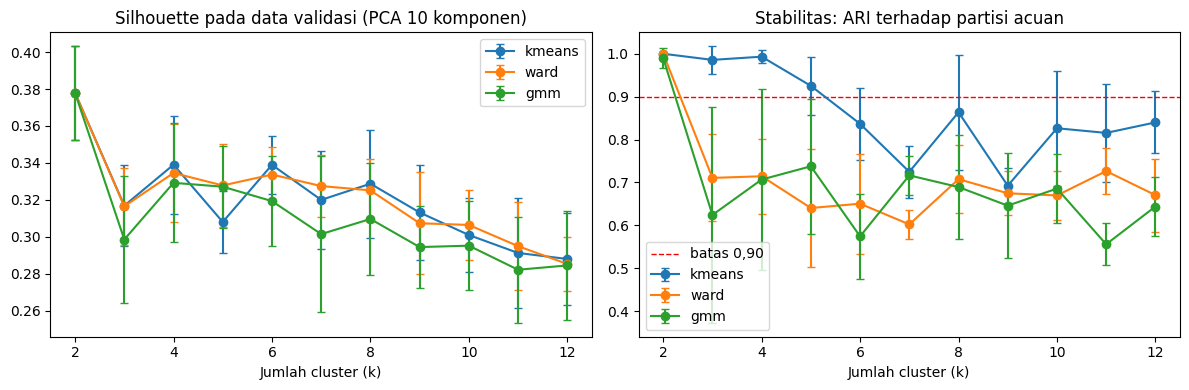

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for metode, warna in zip(["kmeans", "ward", "gmm"], ["tab:blue", "tab:orange", "tab:green"]):
    g = grid[(grid.metode == metode) & (grid.npc == 10)]
    ax[0].errorbar(g.k, g.sil, yerr=g.sil_sd, marker="o", capsize=3, label=metode, color=warna)
    ax[1].errorbar(g.k, g.ari, yerr=g.ari_sd, marker="o", capsize=3, label=metode, color=warna)
ax[0].set_title("Silhouette pada data validasi (PCA 10 komponen)")
ax[1].set_title("Stabilitas: ARI terhadap partisi acuan")
ax[1].axhline(0.90, color="red", ls="--", lw=1, label="batas 0,90")
for a in ax:
    a.set_xlabel("Jumlah cluster (k)")
    a.legend()
plt.tight_layout()
plt.show()

In [11]:
# Aturan pemilihan k baseline: silhouette tertinggi di antara k >= 3 yang stabil (ARI >= 0,90)
kb = grid[(grid.metode == "kmeans") & (grid.npc == 10)].set_index("k")
kandidat_k = kb[(kb.index >= 3) & (kb.ari >= 0.90)]
K_BASELINE = int(kandidat_k.sil.idxmax())
N_PC_BASELINE = 10
print("k terbaik tanpa batasan (silhouette tertinggi):", int(kb.sil.idxmax()))
print("k yang lolos aturan (k >= 3 dan ARI >= 0,90):", kandidat_k.index.tolist())
print("K_BASELINE =", K_BASELINE, "| N_PC_BASELINE =", N_PC_BASELINE)

k terbaik tanpa batasan (silhouette tertinggi): 2
k yang lolos aturan (k >= 3 dan ARI >= 0,90): [3, 4, 5]
K_BASELINE = 4 | N_PC_BASELINE = 10



**Keputusan k baseline = 4.** Silhouette dan stabilitas tertinggi memang ada pada k = 2, tetapi pembagian itu hanya memisahkan sel darah dari sel padat (terlalu sederhana untuk tujuan mencari pola). Karena itu kami memilih k tertinggi silhouette-nya di antara k ≥ 3 yang masih stabil (ARI ≥ 0,90): k = 3, 4, atau 5 lolos, dan k = 4 yang terbaik (Silhouette 0,339, ARI 0,993). Batas k ≥ 3 dan ARI ≥ 0,90 adalah asumsi kami. Jumlah PCA dipakai 10 (nilai tengah; pengaruhnya diuji di Tugas 3).

## 2.3 Hasil validasi baseline per fold


In [12]:
# Tabel hasil validasi per fold untuk baseline
base = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE)

tabel = pd.DataFrame({"Fold": [f"Fold {i}" for i in base.fold],
                      "Silhouette (data validasi)": base.sil.round(3).to_numpy(),
                      "ARI vs partisi acuan": base.ari_ref.round(3).to_numpy(),
                      "Davies-Bouldin": base.db.round(3).to_numpy(),
                      "ARI vs jaringan": base.ari_jaringan.round(3).to_numpy()})
ringkasan = pd.DataFrame({"Fold": ["Rata-rata", "Standar deviasi"],
                          "Silhouette (data validasi)": [base.sil.mean(), base.sil.std()],
                          "ARI vs partisi acuan": [base.ari_ref.mean(), base.ari_ref.std()],
                          "Davies-Bouldin": [base.db.mean(), base.db.std()],
                          "ARI vs jaringan": [base.ari_jaringan.mean(), base.ari_jaringan.std()]}).round(3)
display(pd.concat([tabel, ringkasan], ignore_index=True))

,Fold,Silhouette (data validasi),ARI vs partisi acuan,Davies-Bouldin,ARI vs jaringan
0,Fold 1,0.322,1.000,1.170,0.199
1,Fold 2,0.367,1.000,1.052,0.203
2,Fold 3,0.366,1.000,1.031,0.173
3,Fold 4,0.332,1.000,1.098,0.170
4,Fold 5,0.308,0.966,1.158,0.181
5,Rata-rata,0.339,0.993,1.102,0.185
6,Standar deviasi,0.027,0.015,0.062,0.015


In [13]:
# Apakah hasil tetap stabil bila pembagian data diubah? Ulangi 5-fold CV dengan 5 pengacakan berbeda
rep = []
for s in [1, 2, 3, 4, 5]:
    r = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE, seed_lipatan=s)
    rep.append({"Pengacakan (seed)": s, "Silhouette rata-rata": r.sil.mean(), "ARI rata-rata": r.ari_ref.mean(), "ARI terendah": r.ari_ref.min()})
rep = pd.DataFrame(rep)
display(rep.round(3))
print("Antar pengacakan: Silhouette", f"{rep['Silhouette rata-rata'].mean():.3f} ± {rep['Silhouette rata-rata'].std():.3f}",
      "| ARI", f"{rep['ARI rata-rata'].mean():.3f} ± {rep['ARI rata-rata'].std():.3f}")

,Pengacakan (seed),Silhouette rata-rata,ARI rata-rata,ARI terendah
0,1,0.334,0.989,0.968
1,2,0.332,0.988,0.942
2,3,0.335,0.992,0.958
3,4,0.333,0.953,0.846
4,5,0.332,0.980,0.900


Antar pengacakan: Silhouette 0.333 ± 0.001 | ARI 0.980 ± 0.016



## 2.4 Interpretasi kestabilan

- **Silhouette** per fold berkisar 0,308 sampai 0,367 (rata-rata 0,339, standar deviasi 0,027). Variasinya sekitar 8% dari rata-ratanya, tergolong kecil.
- **Stabilitas (ARI)** per fold 0,966 sampai 1,000 (rata-rata 0,993). Pada empat fold pembagian cluster **identik** dengan model acuan. Artinya sel yang tidak ikut membentuk model tetap jatuh ke cluster yang sama.
- **Pembagian data diubah (5 pengacakan berbeda):** Silhouette rata-rata 0,333 ± 0,001 dan ARI 0,980 ± 0,016. Fold terburuk muncul pada pengacakan ke-4 (ARI 0,846), masih di atas 0,80.
- **Kesimpulan:** pada k = 4 model **relatif stabil** terhadap perubahan pembagian data.
- **Batasan penting:** kestabilan turun saat k membesar. Pada tabel pemilihan k, ARI berada di 0,69 sampai 0,86 untuk k = 6 sampai 12 (semuanya di bawah batas 0,90), terendah 0,692 pada k = 9. Jadi hanya struktur kasar (darah vs padat, ditambah beberapa kelompok sel padat) yang bisa dipercaya. Pembagian lebih halus belum stabil.
- **Kekuatan struktur:** Silhouette 0,34 masuk kategori **lemah sampai sedang**. Cluster ada, tetapi batasnya tidak tegas (dibahas lagi di Tugas 4).
- "ARI vs jaringan" yang rendah (0,185) bukan tanda model buruk: model hanya punya 4 cluster sedangkan jaringan ada 19 kategori, dan ARI memang memberi nilai rendah bila jumlah kelompoknya sangat berbeda. NMI (sekitar 0,45) lebih cocok untuk perbandingan ini.



# Tugas 3. Perbandingan kandidat model dan ensemble

Semua kandidat dinilai pada **fold yang sama, transformasi yang sama, dan k yang sama** (k = 4), sehingga perbandingannya adil. Kandidat dipilih agar menjawab pertanyaan yang relevan bagi proyek:

- **Berapa banyak dimensi PCA yang dibutuhkan?** (5, 20, 50 komponen, dan tanpa PCA.)
- **Apakah metode clustering lain lebih baik?** (Hierarchical Ward dan Gaussian Mixture.)
- **Apakah ensemble membantu?** Consensus clustering menjalankan 50 K-Means pada subsampel 80% dengan jumlah PC acak (5, 10, atau 20), menggabungkannya lewat matriks co-association, lalu memotongnya dengan hierarchical clustering.


In [14]:
# Perbandingan baseline dan kandidat pada fold yang sama (k = K_BASELINE)
konfigurasi = [
    ("Baseline: PCA 10 + K-Means", "kmeans", 10),
    ("K-Means, PCA 5 komponen", "kmeans", 5),
    ("K-Means, PCA 20 komponen", "kmeans", 20),
    ("K-Means, PCA 50 komponen", "kmeans", 50),
    ("K-Means tanpa PCA (2.000 gen)", "kmeans", None),
    ("Hierarchical Ward, PCA 10", "ward", 10),
    ("Gaussian Mixture, PCA 10", "gmm", 10),
    ("Ensemble: consensus clustering", "konsensus", 10),
]
hasil = []
for nama, metode, npc in konfigurasi:
    r = jalankan_cv(metode, K_BASELINE, npc)
    hasil.append({"Model": nama,
                  "Silhouette": mean_sd(r, "sil"), "Davies-Bouldin": mean_sd(r, "db"),
                  "Stabilitas (ARI)": mean_sd(r, "ari_ref"),
                  "ARI vs jaringan": mean_sd(r, "ari_jaringan"), "NMI vs jaringan": mean_sd(r, "nmi_jaringan")})
perbandingan = pd.DataFrame(hasil)
display(perbandingan)

,Model,Silhouette,Davies-Bouldin,Stabilitas (ARI),ARI vs jaringan,NMI vs jaringan
0,Baseline: PCA 10 + K-Means,0.339 ± 0.027,1.102 ± 0.062,0.993 ± 0.015,0.185 ± 0.015,0.451 ± 0.020
1,"K-Means, PCA 5 komponen",0.429 ± 0.033,0.841 ± 0.059,0.975 ± 0.028,0.183 ± 0.014,0.448 ± 0.021
2,"K-Means, PCA 20 komponen",0.282 ± 0.023,1.294 ± 0.073,0.981 ± 0.032,0.186 ± 0.014,0.450 ± 0.022
3,"K-Means, PCA 50 komponen",0.243 ± 0.019,1.445 ± 0.074,0.982 ± 0.026,0.185 ± 0.015,0.451 ± 0.020
4,K-Means tanpa PCA (2.000 gen),0.140 ± 0.013,2.120 ± 0.095,0.982 ± 0.018,0.185 ± 0.015,0.451 ± 0.020
5,"Hierarchical Ward, PCA 10",0.335 ± 0.026,1.115 ± 0.059,0.714 ± 0.088,0.183 ± 0.013,0.448 ± 0.013
6,"Gaussian Mixture, PCA 10",0.329 ± 0.032,1.159 ± 0.119,0.707 ± 0.212,0.179 ± 0.021,0.447 ± 0.032
7,Ensemble: consensus clustering,0.339 ± 0.027,1.102 ± 0.062,0.993 ± 0.015,0.185 ± 0.015,0.451 ± 0.020


In [15]:
# Ensemble vs baseline pada k yang lebih sulit (3 pengacakan fold x 5 fold = 15 skor per sel tabel)
baris = []
for k in [K_BASELINE, 6, 8]:
    for nama, metode in [("K-Means", "kmeans"), ("Consensus", "konsensus")]:
        r = pd.concat([jalankan_cv(metode, k, 10, seed_lipatan=s) for s in [1, 2, 3]])
        baris.append({"k": k, "Metode": nama, "Silhouette": mean_sd(r, "sil"),
                      "Stabilitas (ARI)": mean_sd(r, "ari_ref"), "ARI terendah": round(r.ari_ref.min(), 3),
                      "ARI vs jaringan": mean_sd(r, "ari_jaringan")})
display(pd.DataFrame(baris))

,k,Metode,Silhouette,Stabilitas (ARI),ARI terendah,ARI vs jaringan
0,4,K-Means,0.334 ± 0.027,0.990 ± 0.019,0.942,0.186 ± 0.015
1,4,Consensus,0.334 ± 0.026,0.989 ± 0.021,0.942,0.187 ± 0.015
2,6,K-Means,0.317 ± 0.037,0.834 ± 0.102,0.661,0.265 ± 0.032
3,6,Consensus,0.314 ± 0.039,0.815 ± 0.106,0.619,0.263 ± 0.026
4,8,K-Means,0.333 ± 0.030,0.876 ± 0.106,0.678,0.311 ± 0.042
5,8,Consensus,0.324 ± 0.028,0.824 ± 0.053,0.755,0.319 ± 0.031


In [16]:
# Sensitivitas terhadap asumsi jumlah gen (N_GEN)
baris = []
for n in [500, 1000, 2000, 5000]:
    r = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE, n_gen=n)
    baris.append({"N_GEN": n, "Silhouette": mean_sd(r, "sil"), "Stabilitas (ARI)": mean_sd(r, "ari_ref"),
                  "ARI vs jaringan": mean_sd(r, "ari_jaringan")})
display(pd.DataFrame(baris))

,N_GEN,Silhouette,Stabilitas (ARI),ARI vs jaringan
0,500,0.354 ± 0.026,0.967 ± 0.034,0.182 ± 0.015
1,1000,0.349 ± 0.028,1.000 ± 0.000,0.185 ± 0.015
2,2000,0.339 ± 0.027,0.993 ± 0.015,0.185 ± 0.015
3,5000,0.317 ± 0.022,0.939 ± 0.047,0.174 ± 0.011



## 3.1 Interpretasi perbandingan

**Reduksi dimensi.**
- K-Means dengan PCA 5 komponen punya Silhouette tertinggi (0,429), tetapi itu dihitung pada ruang 5 dimensi sehingga **tidak bisa dibandingkan langsung** dengan baseline (ruang 10 dimensi). Ukuran yang bisa dibandingkan antar-ruang adalah stabilitas (0,975 vs 0,993) dan NMI vs jaringan (0,448 vs 0,451), dan keduanya praktis sama.
- Makin banyak dimensi, Silhouette makin turun (PCA 20: 0,282; PCA 50: 0,243; tanpa PCA: 0,140) dan Davies-Bouldin makin buruk (1,29; 1,45; 2,12), sedangkan stabilitas (sekitar 0,98) dan NMI vs jaringan (0,45) tidak berubah. Artinya struktur utama sama di semua ruang; dimensi tambahan hanya menambah *noise* sehingga cluster tampak kurang rapat. Ini mendukung pemakaian PCA: hasil setara dengan 2.000 gen, tetapi hanya 10 dimensi.

**Metode lain.** Hierarchical Ward dan Gaussian Mixture punya Silhouette setara baseline (0,335 dan 0,329), tetapi **kurang stabil** (ARI 0,714 dan 0,707; Gaussian Mixture bahkan bervariasi besar, ±0,212). Peringatan: sel validasi ditetapkan dengan centroid terdekat, cara yang paling cocok untuk K-Means, sehingga Ward dan GMM bisa tampak kurang stabil sebagian karena cara penetapan ini. Kesimpulannya, tidak ada bukti metode lain lebih baik dari baseline.

**Ensemble.**
- Pada k = 4, consensus clustering menghasilkan angka yang **identik** dengan baseline pada semua metrik. Ke-50 K-Means penyusunnya menemukan pembagian yang sama, jadi tidak ada yang bisa "diperbaiki" oleh penggabungan.
- Pada k yang lebih sulit (15 skor per baris: 3 pengacakan × 5 fold), ensemble **tidak meningkatkan** kinerja. Pada k = 6, ARI 0,815 vs 0,834 (K-Means). Pada k = 8, rata-rata ARI lebih rendah (0,824 vs 0,876) walaupun variasinya lebih kecil (±0,053 vs ±0,106) dan ARI terburuknya lebih tinggi (0,755 vs 0,678). Silhouette sama atau sedikit lebih rendah.
- **Jawaban pertanyaan 2:** ensemble tidak meningkatkan performa dibanding baseline pada data ini. Manfaatnya hanya sedikit mengurangi variasi pada k = 8, belum cukup untuk menggantikan baseline.

## 3.2 Sensitivitas terhadap asumsi jumlah gen

Jumlah gen (N_GEN = 2.000) adalah asumsi, jadi kami mengujinya. Silhouette sedikit naik bila gen lebih sedikit (0,354 pada 500 gen; 0,349 pada 1.000 gen) dan turun pada 5.000 gen (0,317). Stabilitas terbaik pada 1.000 sampai 2.000 gen (1,000 dan 0,993) dan mulai menurun pada 5.000 gen (0,939). ARI vs jaringan hampir sama di semua pilihan (0,174 sampai 0,185). Jadi hasil tidak sensitif terhadap pilihan 2.000, dan 1.000 sampai 2.000 gen sama baiknya.



# Tugas 4 (versi unsupervised). Ukuran dan karakteristik cluster

Karena tidak ada kelas target, analisis "imbalance" diganti dengan empat pemeriksaan: (1) kestabilan hasil clustering (sudah di Tugas 2), (2) perbandingan konfigurasi dan metode (sudah di Tugas 3), (3) ukuran dan karakteristik cluster, serta (4) metrik internal. Bagian ini mengerjakan (3) dan (4), termasuk apakah ketimpangan jumlah sel antar jaringan memengaruhi hasil clustering, dan bagaimana respons obat berbeda antar cluster.

Model baseline di bawah ini dipelajari dari **seluruh development set**. Test set tetap tidak dipakai.


In [17]:
# Ukuran dan karakteristik cluster baseline (model dipelajari dari seluruh development set)
Zd, Pd = siapkan()["ref"]
lab = bagi_klaster("kmeans", Pd[:, :N_PC_BASELINE], K_BASELINE)
jar_asli = metadata.tissue_ccle.to_numpy()[dev]
sil_sel = silhouette_samples(Pd[:, :N_PC_BASELINE], lab)

profil = []
for c in range(K_BASELINE):
    m = lab == c
    top = pd.Series(jar_asli[m]).value_counts()
    profil.append({"Cluster": c, "Jumlah sel": int(m.sum()), "Persen": round(m.mean() * 100, 1),
                   "Silhouette rata-rata": round(sil_sel[m].mean(), 3),
                   "Jumlah jaringan": top.size,
                   "Jaringan dominan": ", ".join(f"{j.replace('HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'DARAH')} {n / m.sum():.0%}" for j, n in top.head(3).items())})
display(pd.DataFrame(profil))

print("Metrik internal pada seluruh development set:",
      "Silhouette =", round(silhouette_score(Pd[:, :N_PC_BASELINE], lab), 3),
      "| Davies-Bouldin =", round(davies_bouldin_score(Pd[:, :N_PC_BASELINE], lab), 3),
      "| Calinski-Harabasz =", round(calinski_harabasz_score(Pd[:, :N_PC_BASELINE], lab), 1))
print("Sel dengan silhouette negatif (mungkin salah cluster):", int((sil_sel < 0).sum()), f"({(sil_sel < 0).mean():.1%})")

,Cluster,Jumlah sel,Persen,Silhouette rata-rata,Jumlah jaringan,Jaringan dominan
0,0,186,37.5,0.284,14,"LUNG 22%, LARGE_INTESTINE 16%, BREAST 15%"
1,1,82,16.5,0.532,1,DARAH 100%
2,2,157,31.7,0.283,20,"LUNG 22%, SKIN 17%, CENTRAL_NERVOUS_SYSTEM 17%"
3,3,71,14.3,0.324,14,"LUNG 44%, AUTONOMIC_GANGLIA 11%, SOFT_TISSUE 7%"


Metrik internal pada seluruh development set: Silhouette = 0.33 | Davies-Bouldin = 1.165 | Calinski-Harabasz = 224.5
Sel dengan silhouette negatif (mungkin salah cluster): 5 (1.0%)


In [18]:
# Apakah ukuran kelompok jaringan memengaruhi cluster? Sebaran tiap jaringan ke cluster
tabel_jar = pd.crosstab(pd.Series(jar_asli, name="jaringan"), pd.Series(lab, name="cluster"))
tabel_jar["total"] = tabel_jar.sum(axis=1)
tabel_jar["porsi_cluster_terbesar"] = (tabel_jar.iloc[:, :K_BASELINE].max(axis=1) / tabel_jar.total).round(2)
display(tabel_jar.sort_values("total", ascending=False))

cluster,0,1,2,3,total,porsi_cluster_terbesar
jaringan,,,,,,
LUNG,40,0,34,31,105,0.38
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0,82,0,0,82,1.00
BREAST,28,0,6,2,36,0.78
LARGE_INTESTINE,30,0,1,1,32,0.94
CENTRAL_NERVOUS_SYSTEM,0,0,26,0,26,1.00
SKIN,0,0,26,0,26,1.00
PANCREAS,18,0,3,1,22,0.82
OVARY,10,0,10,2,22,0.45
OESOPHAGUS,18,0,1,0,19,0.95


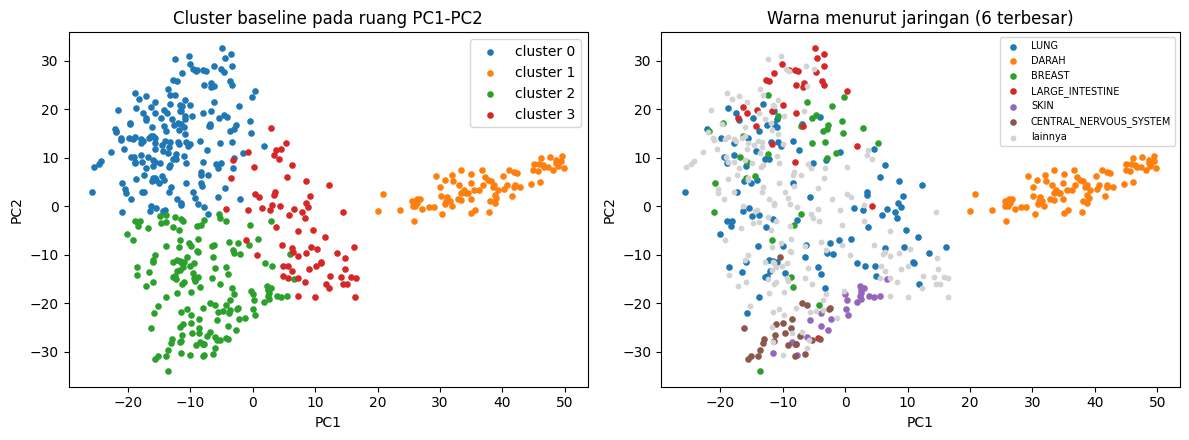

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c in range(K_BASELINE):
    ax[0].scatter(Pd[lab == c, 0], Pd[lab == c, 1], s=14, label=f"cluster {c}")
ax[0].set_title("Cluster baseline pada ruang PC1-PC2")
ax[0].legend()
besar = pd.Series(jar_asli).value_counts().head(6).index
for j in besar:
    m = jar_asli == j
    ax[1].scatter(Pd[m, 0], Pd[m, 1], s=14, label=j.replace("HAEMATOPOIETIC_AND_LYMPHOID_TISSUE", "DARAH"))
ax[1].scatter(Pd[~np.isin(jar_asli, besar), 0], Pd[~np.isin(jar_asli, besar), 1], s=10, c="lightgray", label="lainnya")
ax[1].set_title("Warna menurut jaringan (6 terbesar)")
ax[1].legend(fontsize=7)
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [20]:
# Respons obat per cluster (hanya development set; test set tidak dipakai)
resp_dev = respons[respons.COSMIC_ID.isin(ids[dev])].merge(
    pd.Series(lab, index=ids[dev], name="cluster"), left_on="COSMIC_ID", right_index=True)

def uji_obat(data, nama):
    hasil = []
    for did, g in data.groupby("DRUG_ID"):
        kel = [x.LN_IC50.to_numpy() for _, x in g.groupby("cluster") if len(x) >= 10]
        if len(kel) < 2:
            continue
        H, p = kruskal(*kel)
        n = sum(len(x) for x in kel)
        hasil.append({"DRUG_ID": did, "obat": g.DRUG_NAME.iloc[0], "n_sel": n, "p": p,
                      "ukuran_efek (eta2)": (H - len(kel) + 1) / (n - len(kel))})
    D = pd.DataFrame(hasil)
    D["fdr"] = false_discovery_control(D.p, method="bh")
    print(f"{nama}: {len(D)} obat diuji | FDR < 0,05: {(D.fdr < 0.05).sum()} | FDR < 0,001: {(D.fdr < 0.001).sum()} | median eta2 = {D['ukuran_efek (eta2)'].median():.3f}")
    return D

# (a) semua cluster
D_semua = uji_obat(resp_dev, "Semua cluster")

# (b) tanpa cluster sel darah (agar tidak hanya terlihat perbedaan darah vs padat)
hae = pd.Series(jar_asli == "HAEMATOPOIETIC_AND_LYMPHOID_TISSUE")
klaster_darah = int(pd.Series(lab)[hae.to_numpy()].mode()[0])
print("Cluster sel darah:", klaster_darah)
D_padat = uji_obat(resp_dev[resp_dev.cluster != klaster_darah], "Hanya cluster sel padat")
display(D_padat.sort_values("ukuran_efek (eta2)", ascending=False).head(6).round(4))

Semua cluster: 295 obat diuji | FDR < 0,05: 293 | FDR < 0,001: 288 | median eta2 = 0.216
Cluster sel darah: 1


Hanya cluster sel padat: 295 obat diuji | FDR < 0,05: 241 | FDR < 0,001: 174 | median eta2 = 0.049


,DRUG_ID,obat,n_sel,p,ukuran_efek (eta2),fdr
17,1021,Axitinib,409,0.0,0.1870,0.0000
65,1096,Tozasertib,104,0.0,0.1791,0.0001
106,1549,Sapitinib,411,0.0,0.1788,0.0000
174,1804,Acetalax,318,0.0,0.1674,0.0000
207,1845,Schweinfurthin A,318,0.0,0.1673,0.0000
166,1782,GSK2830371A,318,0.0,0.1647,0.0000



## 4.1 Interpretasi

**Ukuran cluster.** Empat cluster berukuran 186 (37,5%), 82 (16,5%), 157 (31,7%), dan 71 sel (14,3%). Perbandingan terbesar terhadap terkecil hanya 2,6 kali, jadi tidak ada cluster yang sangat kecil atau mendominasi.

**Kualitas dan karakter cluster.**
- **Cluster 1** berisi 82 sel yang **100% sel darah**, dengan Silhouette 0,532: terpisah jelas (terlihat sebagai gugus sendiri di plot PCA).
- **Cluster 0, 2, dan 3** campuran dan batasnya kabur (Silhouette 0,28 sampai 0,32). Di plot PCA ketiganya membentuk sebaran yang bersambung, bukan gugus terpisah. Cluster 0 berisi paru (22%) bersama banyak jaringan epitel (usus besar, payudara, pankreas, esofagus), cluster 2 memuat sistem saraf pusat, kulit, ginjal, dan sebagian paru, cluster 3 memuat paru (44%) bersama ganglia otonom, jaringan lunak, dan tulang. Gambaran ini hanya pengamatan dan belum ditafsirkan secara biologis.
- Ada 5 sel (1,0%) dengan Silhouette negatif, yaitu sel yang mungkin lebih cocok di cluster lain.
- Metrik internal pada seluruh development set: Silhouette 0,330, Davies-Bouldin 1,165, Calinski-Harabasz 224,5.

**Apakah ketimpangan jaringan memengaruhi cluster?**
- Cluster dibentuk terutama oleh jaringan besar. Jaringan yang konsisten satu cluster adalah sistem saraf pusat, kulit, saluran aerodigestif atas, dan ginjal (100%), serta usus besar (94%) dan esofagus (95%).
- Jaringan kecil tidak membentuk cluster sendiri. Tiroid (8 sel), prostat (6), pleura (3), dan serviks (2) tertampung di cluster yang paling dekat.
- Paru, jaringan terbesar (105 sel di development set), justru **tersebar ke tiga cluster** (40, 34, 31 sel; porsi cluster terbesar hanya 38%). Jadi cluster tidak sama dengan jaringan: sel paru yang berbeda subtipe berprofil ekspresi berbeda.
- Ketimpangan ini juga menjelaskan mengapa cluster halus (k besar) tidak stabil: kelompok kecil terlalu sedikit sel untuk membentuk cluster yang konsisten.

## 4.2 Respons obat per cluster (karakteristik awal)

Perbedaan `LN_IC50` antar cluster diuji per obat dengan uji Kruskal-Wallis, dikoreksi *false discovery rate* (FDR). Obat dengan dua `DRUG_ID` dihitung terpisah.

- **Semua cluster:** 293 dari 295 obat berbeda signifikan (FDR < 0,05) dengan ukuran efek median (eta²) 0,216. Hampir seluruh perbedaan ini berasal dari cluster sel darah.
- **Hanya cluster sel padat:** 241 dari 295 obat masih signifikan, tetapi ukuran efeknya **jauh lebih kecil** (median eta² 0,049; tertinggi 0,187 pada Axitinib, lalu Tozasertib, Sapitinib, Acetalax, dan Schweinfurthin A, sekitar 0,17 sampai 0,18).
- **Cara membaca:** dengan ratusan sel, perbedaan kecil pun mudah signifikan, jadi ukuran efek lebih bermakna daripada p-value. Cluster ekspresi menangkap perbedaan sensitivitas obat yang jelas antara sel darah dan sel padat, sedangkan di antara sel padat keterkaitannya lemah sampai sedang. Cluster dan jaringan asal saling bertumpuk, sehingga perbedaan respons belum bisa dipisahkan dari efek jaringan, dan ini **bukan bukti sebab-akibat**.



# Ringkasan hasil dan keterbatasan

## Jawaban tiga pertanyaan milestone

| Pertanyaan | Jawaban singkat | Bukti |
|---|---|---|
| 1. Apakah performa stabil ketika pembagian data berubah? | **Ya pada k = 4**, tidak pada k besar | Silhouette 0,339 ± 0,027 dan ARI 0,993 ± 0,015 antar fold; 0,333 ± 0,001 dan 0,980 ± 0,016 antar 5 pengacakan. ARI turun ke 0,69 sampai 0,86 pada k = 6 sampai 12 |
| 2. Apakah ensemble meningkatkan performa? | **Tidak** | Consensus clustering identik dengan baseline pada k = 4, dan tidak lebih baik pada k = 6 dan 8 |
| 3. Apakah distribusi kelas memengaruhi evaluasi? | Tidak ada kelas target. Ketimpangan **jaringan** memengaruhi bentuk cluster | Jaringan besar membentuk cluster, jaringan kecil tertampung, paru tersebar ke tiga cluster |

## Keterbatasan eksperimen

1. **Data sedikit.** Development set 496 sel, tiap fold validasi sekitar 99 sel, dan banyak jaringan hanya belasan sel. Sebagian variasi antar fold berasal dari ukuran data yang kecil.
2. **Tidak ada label kebenaran.** Silhouette dan ARI menilai kerapatan dan konsistensi, bukan kebenaran biologis. Jaringan hanya pembanding, bukan jawaban benar.
3. **Stabilitas diukur terhadap acuan dari metode yang sama.** Ini mengukur konsistensi diri, dan K-Means diuntungkan oleh penetapan centroid terdekat. Hasil Ward dan Gaussian Mixture mungkin sedikit terlalu pesimis.
4. **Silhouette tidak sebanding antar ruang dimensi.** Perbandingan jumlah PCA hanya valid lewat stabilitas dan NMI.
5. **Pemilihan k memakai aturan buatan kami** (k ≥ 3 dan ARI ≥ 0,90). Aturan lain bisa memilih k berbeda.
6. **Test set belum dipakai**, sehingga belum ada bukti generalisasi akhir.
7. **Uji obat per cluster tidak mengendalikan jaringan** sebagai faktor perancu.
8. **Keterbatasan data dari tahap sebelumnya:** hanya 621 *cell line* (64% GDSC) dengan bias seleksi ringan; *cell line* bukan pasien; kemungkinan *batch effect*; gen dominan `ENSG00000228253.1` belum dipastikan identitasnya.



# Rencana eksperimen Pertemuan 6-7

| Pertemuan | Eksperimen | Tujuan | Bukti keberhasilan |
|---|---|---|---|
| 6 | Visualisasi dan clustering dengan UMAP (dibanding PCA) pada fold yang sama | Menguji apakah reduksi non-linear memberi cluster yang lebih rapat dan sama stabil | Silhouette dan ARI antar fold dibanding baseline, dengan hasil yang tidak berubah banyak terhadap seed |
| 6 | Clustering khusus sel darah (leukemia, lymphoma, myeloma) | Mencari subkelompok di dalam sel darah, sesuai fokus topik | Cluster stabil (ARI ≥ 0,70) dan selaras dengan subtipe di GDSC |
| 6 | Memperbaiki penentuan k: tambahkan gap statistic atau kriteria lain, uji N_GEN 1.000 vs 2.000 | Mengurangi ketergantungan pada aturan pemilihan k buatan sendiri | k yang sama terpilih oleh lebih dari satu kriteria |
| 6 | Pemetaan Ensembl ke simbol gen dan analisis gen pembeda tiap cluster | Menafsirkan cluster secara biologis | Daftar gen pembeda yang masuk akal secara biologis |
| 6-7 | Uji respons obat dengan mengendalikan jaringan (misalnya hanya pada jaringan dengan sel terbanyak) dan memilih obat dengan sel ≥ 300 | Memisahkan efek cluster dari efek jaringan | Perbedaan respons yang tetap ada setelah jaringan dikendalikan |
| 7 | Evaluasi **satu kali** pada test set, dengan konfigurasi final yang sudah dikunci | Bukti generalisasi akhir | Silhouette dan ARI pada test set sejalan dengan hasil fold validasi |
| 7 | Penyusunan laporan akhir | Menyatukan temuan dan keterbatasan | Semua klaim disertai angka dari notebook |



# Checkpoint Pertemuan 5

| Pertanyaan checkpoint | Jawaban |
|---|---|
| **Validasi:** bagaimana model diuji dan mengapa strategi tersebut dipilih? | Data dibagi 80% development dan 20% test (dikunci). Development dinilai dengan 5-fold stratified CV menurut jaringan. Transformasi, PCA, dan clustering dipelajari ulang dari data latih tiap fold. Strategi ini dipilih karena tidak ada target, data sedikit, dan jaringan sangat timpang |
| **Kestabilan:** apakah hasil konsisten antar-fold atau pembagian data? | Ya pada k = 4: ARI 0,993 ± 0,015 antar fold dan 0,980 ± 0,016 antar 5 pengacakan. Tidak stabil pada k ≥ 6 (ARI 0,69 sampai 0,86) |
| **Perbandingan:** apakah kandidat baru memberi manfaat dibanding baseline? | Tidak. PCA lain, Ward, Gaussian Mixture, dan consensus clustering tidak lebih baik dari PCA 10 + K-Means. Ensemble identik dengan baseline pada k = 4 |
| **Imbalance:** apakah distribusi kelas memengaruhi evaluasi? | Tidak ada kelas target. Ketimpangan jaringan memengaruhi cluster: jaringan besar membentuk cluster, jaringan kecil tertampung, paru tersebar ke 3 cluster |
| **Keputusan:** apa yang akan diperbaiki dan apa buktinya? | (1) Tetap memakai PCA 10 + K-Means, k = 4, karena paling stabil. (2) Fokus ke struktur yang lebih halus pada sel darah dan menguji UMAP di Pertemuan 6, karena cluster sel padat batasnya kabur (Silhouette 0,28 sampai 0,32). (3) Mengendalikan jaringan pada uji respons obat, karena perbedaan respons bertumpuk dengan jaringan. (4) Memakai test set sekali di Pertemuan 7 |
